# 03 — Exploratory Data Analysis

Explore the processed smartphone sensor dataset before feature engineering and modelling.

This notebook uses the merged 50 Hz session files produced by `02_preprocessing_and_merging.ipynb`.

**Inputs:**
- `data/interim/sessions_index.csv`
- `data/interim/<session_id>.csv`
- `data/reports/preprocessing_log.csv`

**What this notebook does:**

1. Loads the processed and merged session datasets produced by Notebook 02.
2. Summarises the dataset structure: participants, transport modes, sessions, recording durations, and class balance.
3. Creates interpretable motion features:
   - accelerometer magnitude,
   - linear-accelerometer magnitude,
   - gyroscope magnitude.
4. Investigates per-axis movement structure that is hidden by magnitude features.
5. Visualises representative sensor signals at both full-session and short-term time scales.
6. Explores frequency-domain characteristics using FFT computed on 5-second windows (matching the modelling pipeline).
7. Evaluates participant consistency to assess whether transport-mode patterns remain stable across individuals.
8. Projects session-level summary features to a 2D PCA scatter to assess overall class separability.
9. Inspects barometer signals where available (informative for vehicular modes that change altitude).
10. Synthesises findings and explicitly links them to upcoming feature-engineering choices.

**Key questions addressed:**
- How balanced is the dataset across transport modes?
- Which transport modes exhibit the strongest movement patterns?
- Are the transport modes distinguishable in the time and frequency domains?
- How consistent are the observed patterns across participants?
- Which feature families should we prioritise in the next notebook?

**Important:** This notebook does not preprocess the raw data again. It assumes Notebooks 01 and 02 have already been executed successfully.

## 0. Imports

In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.fft import rfft, rfftfreq
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 80)
pd.set_option('display.width', 200)

## 0.1 Configuration

Paths are relative to the `notebooks/` folder following the repository structure from the project plan. They work for every team member without modification.

In [3]:
# --- paths (relative to notebooks/) ---
INTERIM_DIR     = Path('../data/interim')
REPORTS_DIR     = Path('../reports')
FIGURES_DIR     = REPORTS_DIR / 'figures'
EDA_OUTPUT_DIR  = REPORTS_DIR / 'eda'

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
EDA_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# --- expected protocol ---
PARTICIPANTS = ['babis', 'athina', 'xiomara']
MODES        = ['stationary', 'walking', 'cycling', 'metro', 'bus', 'tram']
DAYS         = ['day1', 'day2', 'day3']

# --- analysis constants ---
WINDOW_SECONDS  = 5     # matches the modelling pipeline
SAMPLING_RATE   = 50    # set by preprocessing notebook (data/reports/preprocessing_log.csv)
WINDOW_SAMPLES  = WINDOW_SECONDS * SAMPLING_RATE

# Pick one participant whose sessions are used as visual representatives.
# Using the same participant for all 'representative' plots isolates mode characteristics
# from individual variation.
REPRESENTATIVE_PARTICIPANT = 'babis'

print(f'INTERIM_DIR    : {INTERIM_DIR.resolve()}')
print(f'REPORTS_DIR    : {REPORTS_DIR.resolve()}')
print(f'FIGURES_DIR    : {FIGURES_DIR.resolve()}')
print(f'EDA_OUTPUT_DIR : {EDA_OUTPUT_DIR.resolve()}')
print(f'Window         : {WINDOW_SECONDS}s at {SAMPLING_RATE}Hz = {WINDOW_SAMPLES} samples')
print(f'Representative participant for visual examples: {REPRESENTATIVE_PARTICIPANT}')

INTERIM_DIR    : C:\Projects\this project-transport-mode\data\interim
REPORTS_DIR    : C:\Projects\this project-transport-mode\reports
FIGURES_DIR    : C:\Projects\this project-transport-mode\reports\figures
EDA_OUTPUT_DIR : C:\Projects\this project-transport-mode\reports\eda
Window         : 5s at 50Hz = 250 samples
Representative participant for visual examples: babis


## 1. Load session index

The file `sessions_index.csv` tells us which sessions were successfully processed by Notebook 02.

Each row corresponds to one processed recording session and includes metadata such as participant, mode, day, duration, and file path.

This index is the starting point for the EDA.

In [4]:
sessions_path = INTERIM_DIR / 'sessions_index.csv'

if not sessions_path.exists():
    raise FileNotFoundError(
        f'Could not find {sessions_path}. '
        'Run Notebook 02 before running this EDA notebook.'
    )

sessions = pd.read_csv(sessions_path)

print(f'Loaded sessions: {len(sessions)}')
display(sessions.head())
display(sessions.tail())

Loaded sessions: 54


,session_id,participant,mode,day,status,notes,sensors_found,duration_s,n_samples,has_barometer,rate_in_acc,rate_in_lin,rate_in_gyr,duplicates_dropped_total,max_gap_s,n_samples_bad,n_samples_flagged,n_gaps_bad,n_gaps_flagged,file_path
0,babis_stationary_day1,babis,stationary,day1,OK,NaN,"accelerometer,barometer,gyroscope,linear_accel...",704.0,35201,True,100.30,100.30,100.30,0,1.063,0,0,0,0,data/interim/babis_stationary_day1.csv
1,babis_stationary_day2,babis,stationary,day2,OK,NaN,"accelerometer,barometer,gyroscope,linear_accel...",705.9,35295,True,100.30,100.30,100.30,0,1.063,0,0,0,0,data/interim/babis_stationary_day2.csv
2,babis_stationary_day3,babis,stationary,day3,OK,NaN,"accelerometer,barometer,gyroscope,linear_accel...",704.3,35216,True,100.31,100.31,100.31,0,1.063,0,0,0,0,data/interim/babis_stationary_day3.csv
3,babis_walking_day1,babis,walking,day1,OK,NaN,"accelerometer,barometer,gyroscope,linear_accel...",410.4,20522,True,100.29,100.29,100.29,0,1.063,0,0,0,0,data/interim/babis_walking_day1.csv
4,babis_walking_day2,babis,walking,day2,OK,NaN,"accelerometer,barometer,gyroscope,linear_accel...",704.3,35217,True,100.30,100.30,100.30,0,1.062,0,0,0,0,data/interim/babis_walking_day2.csv


,session_id,participant,mode,day,status,notes,sensors_found,duration_s,n_samples,has_barometer,rate_in_acc,rate_in_lin,rate_in_gyr,duplicates_dropped_total,max_gap_s,n_samples_bad,n_samples_flagged,n_gaps_bad,n_gaps_flagged,file_path
49,xiomara_bus_day2,xiomara,bus,day2,OK,NaN,"accelerometer,barometer,gyroscope,linear_accel...",441.2,22059,True,50.00,52.96,52.96,18,0.076,0,0,0,0,data/interim/xiomara_bus_day2.csv
50,xiomara_bus_day3,xiomara,bus,day3,OK,NaN,"accelerometer,barometer,gyroscope,linear_accel...",485.1,24254,True,52.96,52.96,52.96,0,0.040,0,0,0,0,data/interim/xiomara_bus_day3.csv
51,xiomara_tram_day1,xiomara,tram,day1,OK,NaN,"accelerometer,barometer,gyroscope,linear_accel...",716.5,35824,True,50.00,52.96,52.96,49,0.040,0,0,0,0,data/interim/xiomara_tram_day1.csv
52,xiomara_tram_day2,xiomara,tram,day2,OK,NaN,"accelerometer,barometer,gyroscope,linear_accel...",620.9,31044,True,52.96,52.96,52.96,0,0.040,0,0,0,0,data/interim/xiomara_tram_day2.csv
53,xiomara_tram_day3,xiomara,tram,day3,OK,NaN,"accelerometer,barometer,gyroscope,linear_accel...",697.8,34893,True,52.96,52.96,52.96,0,0.040,0,0,0,0,data/interim/xiomara_tram_day3.csv


## 2. Verify that all processed session files exist

Before analysing the data, we check whether every file listed in sessions_index.csv actually exists.
This prevents silent errors later in the notebook.

In [5]:
def resolve_session_path(file_path):
    """Resolve file paths saved in sessions_index.csv against several plausible roots."""
    path = Path(file_path)
    if path.exists():
        return path
    alt_path = Path('..') / path
    if alt_path.exists():
        return alt_path
    return INTERIM_DIR / path.name


sessions['resolved_path'] = sessions['file_path'].apply(resolve_session_path)
sessions['file_exists']   = sessions['resolved_path'].apply(lambda p: p.exists())

missing_files = sessions[~sessions['file_exists']]

print(f'Session files found: {sessions["file_exists"].sum()} of {len(sessions)}')

if len(missing_files) > 0:
    print('Missing files:')
    print(missing_files[['session_id', 'file_path', 'resolved_path']].to_string(index=False))
else:
    print('All processed session files exist.')

Session files found: 54 of 54
All processed session files exist.


## 3. Load all processed sessions

We now load every merged session CSV into one combined dataframe.

A column is added for:
- participant
- mode
- day
- session_id

This creates one large analysis table while still preserving the session identity.

In [6]:
all_dfs = []
for _, row in sessions.iterrows():
    path = row['resolved_path']
    if not path.exists():
        continue
    df = pd.read_csv(path)
    df['participant'] = row['participant']
    df['mode']        = row['mode']
    df['day']         = row['day']
    df['session_id']  = row['session_id']
    all_dfs.append(df)

if len(all_dfs) == 0:
    raise ValueError('No session files could be loaded.')

data = pd.concat(all_dfs, ignore_index=True)

print(f'Combined dataset shape  : {data.shape}')
print(f'Sessions loaded         : {data["session_id"].nunique()}')
print(f'Participants            : {sorted(data["participant"].unique())}')
print(f'Transport modes         : {sorted(data["mode"].unique())}')
data.head()

Combined dataset shape  : (1824246, 17)
Sessions loaded         : 54
Participants            : ['athina', 'babis', 'xiomara']
Transport modes         : ['bus', 'cycling', 'metro', 'stationary', 'tram', 'walking']


,t,ax,ay,az,lin_ax,lin_ay,lin_az,gx,gy,gz,pressure,bad_sample,flagged_sample,participant,mode,day,session_id
0,0.00,7.47208,1.66663,6.09152,-0.06489,0.23889,-0.02282,-0.01008,-0.01434,0.00163,1001.90121,False,False,babis,stationary,day1,babis_stationary_day1
1,0.02,7.48444,1.62426,6.08074,-0.06011,0.18169,-0.03229,-0.01007,-0.02132,-0.00028,1001.90128,False,False,babis,stationary,day1,babis_stationary_day1
2,0.04,7.50223,1.60847,6.06914,-0.03908,0.16727,-0.04060,-0.00947,-0.02803,-0.00162,1001.90134,False,False,babis,stationary,day1,babis_stationary_day1
3,0.06,7.50035,1.61739,6.05323,-0.03672,0.17089,-0.04167,-0.01000,-0.03328,0.00010,1001.90141,False,False,babis,stationary,day1,babis_stationary_day1
4,0.08,7.53931,1.62547,6.03855,-0.00839,0.17381,-0.05240,-0.00891,-0.03555,0.00011,1001.90147,False,False,babis,stationary,day1,babis_stationary_day1


## 4. Basic dataset overview 

This section summarises the processed dataset.

We inspect:
- number of participants,
- number of modes,
- number of sessions,
- total number of samples,
- total recording duration.

Because the data was resampled to 50 Hz, each row represents approximately 0.02 seconds of sensor data.

In [7]:
overview = pd.DataFrame({
    'quantity': [
        'participants',
        'transport modes',
        'processed sessions',
        'total samples',
        'total duration (minutes)',
    ],
    'value': [
        data['participant'].nunique(),
        data['mode'].nunique(),
        data['session_id'].nunique(),
        len(data),
        round(data.groupby('session_id')['t'].max().sum() / 60, 2),
    ],
})

overview.to_csv(EDA_OUTPUT_DIR / 'eda_dataset_overview.csv', index=False)
overview

,quantity,value
0,participants,3.00
1,transport modes,6.00
2,processed sessions,54.00
3,total samples,1824246.00
4,total duration (minutes),608.06


### 4.1 Sensor availability and native sampling rates.

In [8]:
sensor_availability = (
    sessions.groupby('participant')
    .agg(
        n_sessions       = ('session_id',     'nunique'),
        accelerometer    = ('rate_in_acc',    lambda x: 'yes' if x.notna().all() else 'partial'),
        linear_acc       = ('rate_in_lin',    lambda x: 'yes' if x.notna().all() else 'partial'),
        gyroscope        = ('rate_in_gyr',    lambda x: 'yes' if x.notna().all() else 'partial'),
        barometer        = ('has_barometer',  lambda x: 'yes' if x.all() else ('no' if not x.any() else 'partial')),
        native_rate_hz   = ('rate_in_acc',    'mean'),
    )
    .round({'native_rate_hz': 1})
)
sensor_availability.to_csv(EDA_OUTPUT_DIR / 'eda_sensor_availability.csv')
print('Sensor availability and native sampling rate per participant:')
sensor_availability

Sensor availability and native sampling rate per participant:


,n_sessions,accelerometer,linear_acc,gyroscope,barometer,native_rate_hz
participant,,,,,,
athina,18,yes,yes,yes,no,50.0
babis,18,yes,yes,yes,yes,100.3
xiomara,18,yes,yes,yes,yes,52.1


**Comment:** this table documents the device/sampling-rate confound described in plan §9 and motivates why E2 (LOSO) is interpreted as a combined user + device + native-rate shift.

## 5. Dataset balance 

Before examining the sensor signals, we first inspect how the dataset is distributed across transport modes.

Balanced datasets generally make classification easier because each class contributes a similar amount of training data.

We therefore examine:

- number of recording sessions per mode,
- total duration per mode,
- total number of samples per mode.

This helps us identify any over- or under-represented transport modes.

In [9]:
session_counts    = sessions.groupby('mode').size().reindex(MODES)
duration_per_mode = sessions.groupby('mode')['duration_s'].sum().reindex(MODES)
sample_counts     = data.groupby('mode').size().reindex(MODES)

balance_df = pd.DataFrame({
    'sessions':   session_counts,
    'duration_s': duration_per_mode,
    'samples':    sample_counts,
})
balance_df.to_csv(EDA_OUTPUT_DIR / 'eda_class_balance.csv', index=True)
balance_df

,sessions,duration_s,samples
mode,,,
stationary,9,6310.9,315554
walking,9,5486.7,274339
cycling,9,6270.1,313516
metro,9,6405.9,320301
bus,9,5840.5,292036
tram,9,6169.9,308500


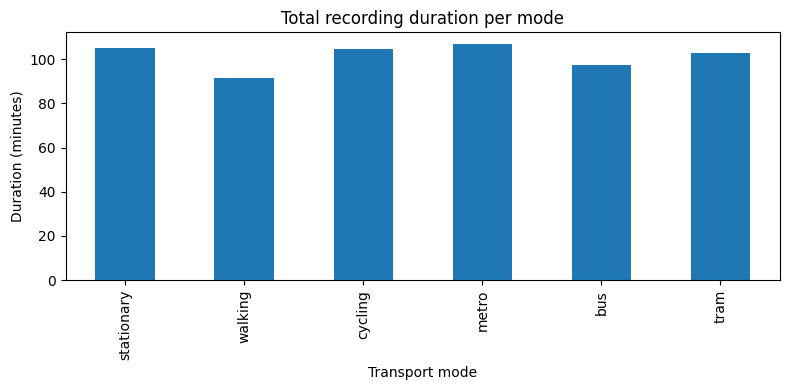

In [10]:
plt.figure(figsize=(8, 4))
(duration_per_mode / 60).plot(kind='bar')
plt.title('Total recording duration per mode')
plt.xlabel('Transport mode')
plt.ylabel('Duration (minutes)')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_duration_per_mode.png', dpi=300, bbox_inches='tight')
plt.show()

### Discussion of dataset balance

The dataset is well balanced at the session level, with 6 sessions per transport mode (3 participants × 2 days). Total recording durations differ slightly because of natural variability in trip lengths, especially for the public-transport modes where the recording length is determined by the actual journey. Walking has the least total data and cycling and metro the most, but the difference is modest (~60–75 minutes per mode). Because session counts are identical across modes, class imbalance during model training is unlikely to be a serious problem; With a window-level imbalance ratio of 1.19 — well below the 2× threshold from plan §33.2 — macro-F1 without resampling is sufficient, and no class-weighting is required.

## 6. Signal magnitude analysis

Smartphone motion sensors record movement along three axes (x, y, z).

Because the phone may be carried in different orientations (hand, pocket, bag, etc.), analysing each axis separately can make interpretation difficult.

A common approach in activity-recognition research is to compute the signal magnitude:

- accelerometer magnitude
- linear-accelerometer magnitude
- gyroscope magnitude

The magnitude combines the three axes into a single measure of movement intensity.

This makes the signals easier to compare across participants and transport modes.

In this section we create magnitude features that will be used throughout the remainder of the EDA.

In [11]:
data['acc_mag']     = np.sqrt(data['ax']**2 + data['ay']**2 + data['az']**2)
data['lin_acc_mag'] = np.sqrt(data['lin_ax']**2 + data['lin_ay']**2 + data['lin_az']**2)
data['gyro_mag']    = np.sqrt(data['gx']**2 + data['gy']**2 + data['gz']**2)

print('Magnitude features created.')
data[['acc_mag', 'lin_acc_mag', 'gyro_mag']].describe().round(3)

Magnitude features created.


,acc_mag,lin_acc_mag,gyro_mag
count,1824246.000,1824246.000,1824246.000
mean,9.937,1.130,0.357
std,1.662,1.941,0.659
min,0.392,0.000,0.000
25%,9.694,0.070,0.011
50%,9.813,0.326,0.041
75%,10.006,1.259,0.379
max,44.838,38.027,7.595


### 6.1 Window-level descriptive statistics

The classification model will operate on 5-second windows rather than raw samples. 
We therefore aggregate to window-level summary statistics before computing per-mode descriptives, 
which keeps the EDA numbers consistent with what the model will actually see.

We compute:

- mean: average movement intensity,
- median: typical movement intensity,
- standard deviation: variability over time,
- IQR: spread of the middle 50% of values.

These statistics help us understand whether the transport modes differ in their overall movement intensity.

In [12]:
def window_indices(n_samples, window_samples, step):
    return [(i, i + window_samples) for i in range(0, n_samples - window_samples + 1, step)]

STEP = WINDOW_SAMPLES // 2  # 50% overlap, same as modelling pipeline

window_rows = []
dropped_rows = []

for sid, sdf in data.groupby('session_id'):
    sdf = sdf.reset_index(drop=True)
    meta = {
        'session_id':  sid,
        'participant': sdf['participant'].iloc[0],
        'mode':        sdf['mode'].iloc[0],
        'day':         sdf['day'].iloc[0],
    }
    for start, end in window_indices(len(sdf), WINDOW_SAMPLES, STEP):
        w = sdf.iloc[start:end]

        # drop windows that contain any bad sample (gap > 0.5s)
        if w['bad_sample'].any():
            dropped_rows.append({
                **meta,
                'win_start_s':    float(w['t'].iloc[0]),
                'n_bad_samples':  int(w['bad_sample'].sum()),
                'reason':         'gap > 0.5s',
            })
            continue

        window_rows.append({
            **meta,
            'win_start_s':    float(w['t'].iloc[0]),
            'lin_acc_mag_mean':   float(w['lin_acc_mag'].mean()),
            'lin_acc_mag_std':    float(w['lin_acc_mag'].std()),
            'lin_acc_mag_median': float(w['lin_acc_mag'].median()),
            'lin_acc_mag_iqr':    float(np.percentile(w['lin_acc_mag'], 75) - np.percentile(w['lin_acc_mag'], 25)),
            'gyro_mag_mean':      float(w['gyro_mag'].mean()),
            'gyro_mag_std':       float(w['gyro_mag'].std()),
        })

windows_df = pd.DataFrame(window_rows)
dropped_df = pd.DataFrame(dropped_rows)

windows_df.to_csv(EDA_OUTPUT_DIR / 'eda_windows_summary.csv',  index=False)
dropped_df.to_csv(EDA_OUTPUT_DIR / 'eda_windows_dropped.csv',  index=False)

print(f'Total windows kept:    {len(windows_df)}')
print(f'Total windows dropped: {len(dropped_df)}')
print()
print('Windows kept per mode:')
print(windows_df.groupby('mode').size().reindex(MODES).to_string())
print()
print('Windows dropped per participant / mode:')
if len(dropped_df) > 0:
    print(dropped_df.groupby(['participant', 'mode']).size().to_string())
else:
    print('  none')

Total windows kept:    14513
Total windows dropped: 0

Windows kept per mode:
mode
stationary    2511
walking       2180
cycling       2495
metro         2549
bus           2323
tram          2455

Windows dropped per participant / mode:
  none


#### Window-level balance and per-participant coverage.

In [13]:
# Per-participant × per-mode window counts (plan §33.2)
window_counts_pm = (
    windows_df.groupby(['participant', 'mode']).size()
    .unstack().reindex(columns=MODES).fillna(0).astype(int)
)
window_counts_pm['total'] = window_counts_pm.sum(axis=1)
window_counts_pm.loc['total'] = window_counts_pm.sum(axis=0)
window_counts_pm.to_csv(EDA_OUTPUT_DIR / 'eda_windows_per_participant_mode.csv')
print('Windows per participant × mode:')
print(window_counts_pm.to_string())
print()

# Imbalance ratio at the mode level (plan §33.2 threshold = 2.0)
mode_counts = windows_df.groupby('mode').size().reindex(MODES)
ratio = mode_counts.max() / mode_counts.min()
print(f'Window-level class-imbalance ratio (max/min): {ratio:.2f}')
if ratio > 2.0:
    print('  -> above 2x threshold; commit to macro-F1 OR class-weighted training.')
else:
    print('  -> below 2x threshold; macro-F1 without resampling is sufficient.')

Windows per participant × mode:
mode         stationary  walking  cycling  metro   bus  tram  total
participant                                                        
athina              703      689      727    906   881   810   4716
babis               841      723      852    840   828   835   4919
xiomara             967      768      916    803   614   810   4878
total              2511     2180     2495   2549  2323  2455  14513

Window-level class-imbalance ratio (max/min): 1.17
  -> below 2x threshold; macro-F1 without resampling is sufficient.


In [14]:
def iqr(x):
    return np.percentile(x, 75) - np.percentile(x, 25)

magnitude_summary = (
    windows_df.groupby('mode')[['lin_acc_mag_mean', 'lin_acc_mag_std', 'gyro_mag_mean', 'gyro_mag_std']]
    .agg(['mean', 'median', 'std', iqr])
    .round(3)
    .reindex(MODES)
)
magnitude_summary.to_csv(EDA_OUTPUT_DIR / 'eda_magnitude_summary.csv')
magnitude_summary

lin_acc_mag_mean                      lin_acc_mag_std                      gyro_mag_mean                      gyro_mag_std                     
                       mean median    std    iqr            mean median    std    iqr          mean median    std    iqr         mean median    std    iqr
mode                                                                                                                                                      
stationary            0.046  0.035  0.043  0.039           0.031  0.019  0.044  0.028         0.013  0.008  0.020  0.012        0.011  0.005  0.030  0.008
walking               4.315  3.814  1.659  2.841           2.123  1.602  1.088  1.951         1.233  1.063  0.710  1.431        0.547  0.425  0.308  0.605
cycling               1.650  1.490  0.785  1.127           0.987  0.887  0.571  0.802         0.818  0.742  0.463  0.917        0.423  0.459  0.205  0.381
metro                 0.248  0.189  0.219  0.200           0.127  0.101  0.128  0.095         0.039  0.025  0.075  0.029        0.027  0.014  0.060  0.016
bus                   0.594  0.518  0.462  0.745           0.333  0.275  0.264  0.357         0.082  0.057  0.087  0.101        0.058  0.038  0.079  0.064
tram                  0.299  0.224  0.260  0.278           0.167  0.125  0.162  0.135         0.047  0.025  0.071  0.038        0.033  0.017  0.057  0.028

### 6.2 Linear-accelerometer magnitude by transport mode

The linear-accelerometer magnitude is the most useful signal for comparing movement intensity because it removes the effect of gravity.

The boxplot shows the median and spread of movement intensity for each transport mode.

Outliers are hidden in this plot to make the central distributions easier to compare.

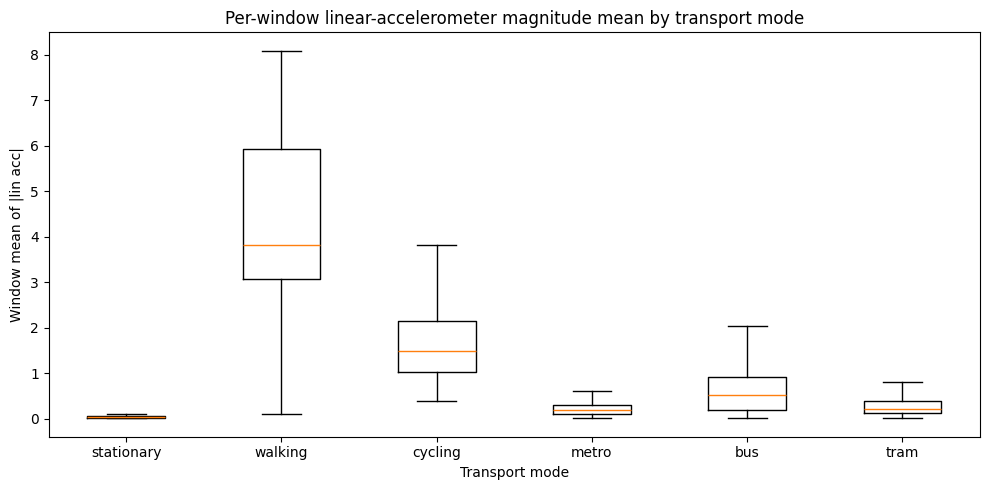

In [15]:
plt.figure(figsize=(10, 5))
plot_data = [windows_df.loc[windows_df['mode'] == m, 'lin_acc_mag_mean'] for m in MODES]
plt.boxplot(plot_data, tick_labels=MODES, showfliers=False)
plt.title('Per-window linear-accelerometer magnitude mean by transport mode')
plt.xlabel('Transport mode')
plt.ylabel('Window mean of |lin acc|')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_lin_acc_mag_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

### 6.3 Distribution shape of linear-accelerometer magnitude

The boxplot summarises each distribution, but it does not show the full shape of the data.

A violin plot provides an additional view by showing where values are most densely concentrated.

This is useful for sensor data because some transport modes may have skewed or multi-peaked distributions.

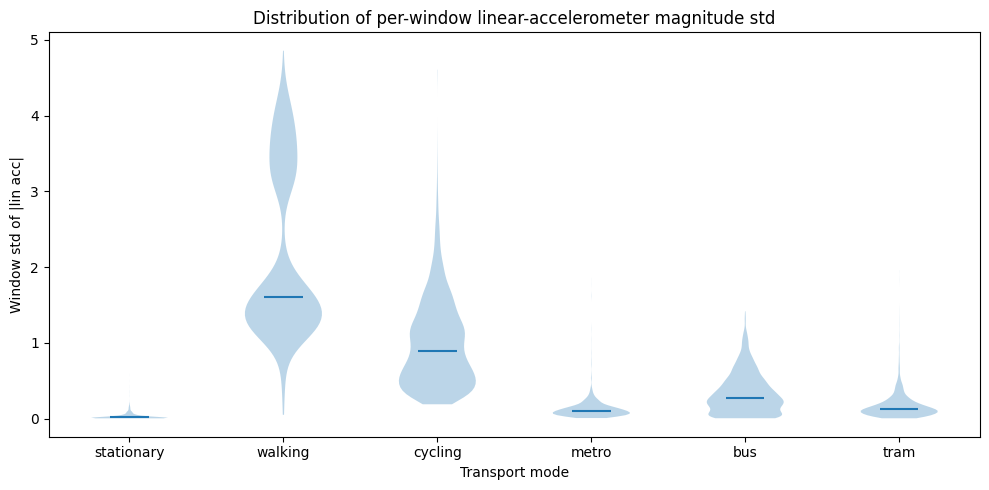

In [16]:
plt.figure(figsize=(10, 5))
plot_data = [windows_df.loc[windows_df['mode'] == m, 'lin_acc_mag_std'] for m in MODES]
parts = plt.violinplot(plot_data, showmeans=False, showmedians=True, showextrema=False)
plt.xticks(ticks=np.arange(1, len(MODES) + 1), labels=MODES)
plt.title('Distribution of per-window linear-accelerometer magnitude std')
plt.xlabel('Transport mode')
plt.ylabel('Window std of |lin acc|')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_lin_acc_mag_violin.png', dpi=300, bbox_inches='tight')
plt.show()

### 6.4 Gyroscope magnitude by transport mode

The gyroscope measures rotational motion.

Comparing gyroscope magnitude across transport modes helps determine whether modes differ not only in linear movement but also in rotational movement.

This is useful because walking and cycling may involve more phone rotation than public-transport modes.

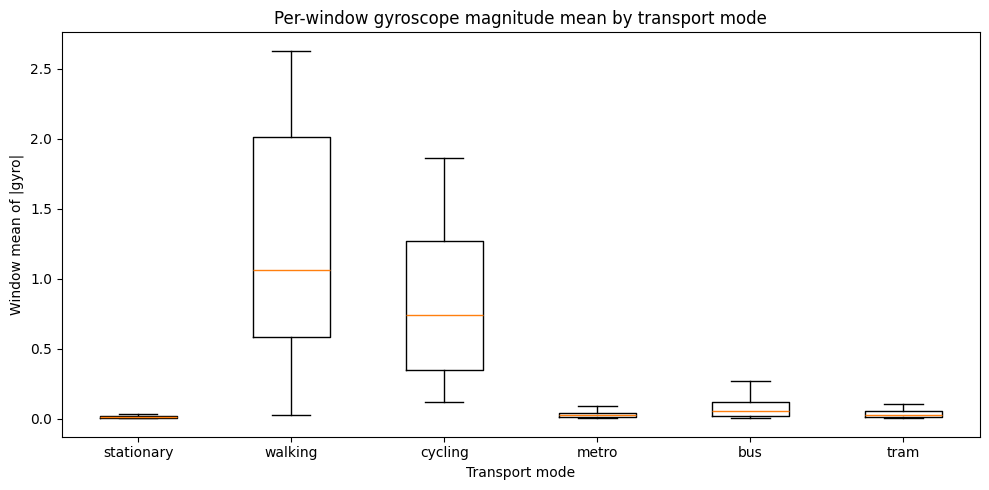

In [17]:
plt.figure(figsize=(10, 5))
plot_data = [windows_df.loc[windows_df['mode'] == m, 'gyro_mag_mean'] for m in MODES]
plt.boxplot(plot_data, tick_labels=MODES, showfliers=False)
plt.title('Per-window gyroscope magnitude mean by transport mode')
plt.xlabel('Transport mode')
plt.ylabel('Window mean of |gyro|')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_gyro_mag_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

### Discussion of magnitude analysis

The magnitude analysis confirms clear differences in movement intensity between transport modes when summarised at the window level.

Stationary windows show the lowest values for both linear-accelerometer and gyroscope magnitude. The median window std for stationary is close to zero, indicating that most stationary samples contain very little movement. Walking is the most dynamic mode: it has the highest window-level mean and median magnitudes for both linear acceleration and rotation, and the widest spread, reflecting the strong, repetitive whole-body motion of stepping. Cycling also shows elevated movement, but its magnitudes sit clearly below walking's, suggesting that walking and cycling should both be cleanly separable from the lower-motion classes while remaining distinguishable from each other.

The public-transport modes have substantially lower magnitudes than walking and cycling. Bus has a somewhat higher median and wider spread than metro and tram, which is plausible because buses are exposed to road surface vibrations, braking, turns, and stop-and-go traffic. However, the distributions for bus, metro, and tram still overlap considerably, suggesting that these modes may be difficult to distinguish using magnitude information alone.

The violin plot adds an important detail: the distributions are strongly right-skewed. Most windows in the public-transport modes concentrate at low magnitudes, but occasional high-magnitude windows appear as narrow upper tails. These likely correspond to short bursts of movement: acceleration, braking, bumps, or phone movement. This confirms that mean values alone are not sufficient — median and IQR are more robust summaries, and features that capture distributional shape (skewness, percentiles, peak-counts) may improve the classifier's ability to separate the public-transport modes.

## 7. Per-axis movement structure

Magnitude features are rotation-invariant by construction and therefore discard information about *which* axis carries the motion.
Walking has dominantly vertical accelerometer signal; cycling has different axis patterns; vehicles tend to show characteristic axis distributions depending on the direction of travel and the user's pose. This section reveals what magnitudes hide.

In [18]:
# Per-window std on each individual axis
axis_rows = []
for sid, sdf in data.groupby('session_id'):
    sdf = sdf.reset_index(drop=True)
    mode = sdf['mode'].iloc[0]
    for start, end in window_indices(len(sdf), WINDOW_SAMPLES, STEP):
        w = sdf.iloc[start:end]
        if w['bad_sample'].any():   # ← add this
            continue
        axis_rows.append({
            'mode': mode,
            'lin_ax_std': float(w['lin_ax'].std()),
            'lin_ay_std': float(w['lin_ay'].std()),
            'lin_az_std': float(w['lin_az'].std()),
            'gx_std':     float(w['gx'].std()),
            'gy_std':     float(w['gy'].std()),
            'gz_std':     float(w['gz'].std()),
        })
axis_df = pd.DataFrame(axis_rows)

axis_mode_summary = axis_df.groupby('mode').median().reindex(MODES).round(3)
axis_mode_summary.to_csv(EDA_OUTPUT_DIR / 'eda_per_axis_summary.csv')
axis_mode_summary

,lin_ax_std,lin_ay_std,lin_az_std,gx_std,gy_std,gz_std
mode,,,,,,
stationary,0.019,0.016,0.016,0.004,0.008,0.003
walking,1.952,3.225,1.732,0.547,0.909,0.414
cycling,1.084,0.860,0.791,0.347,0.450,0.457
metro,0.106,0.091,0.108,0.013,0.020,0.009
bus,0.213,0.263,0.278,0.036,0.042,0.021
tram,0.115,0.126,0.125,0.014,0.023,0.010


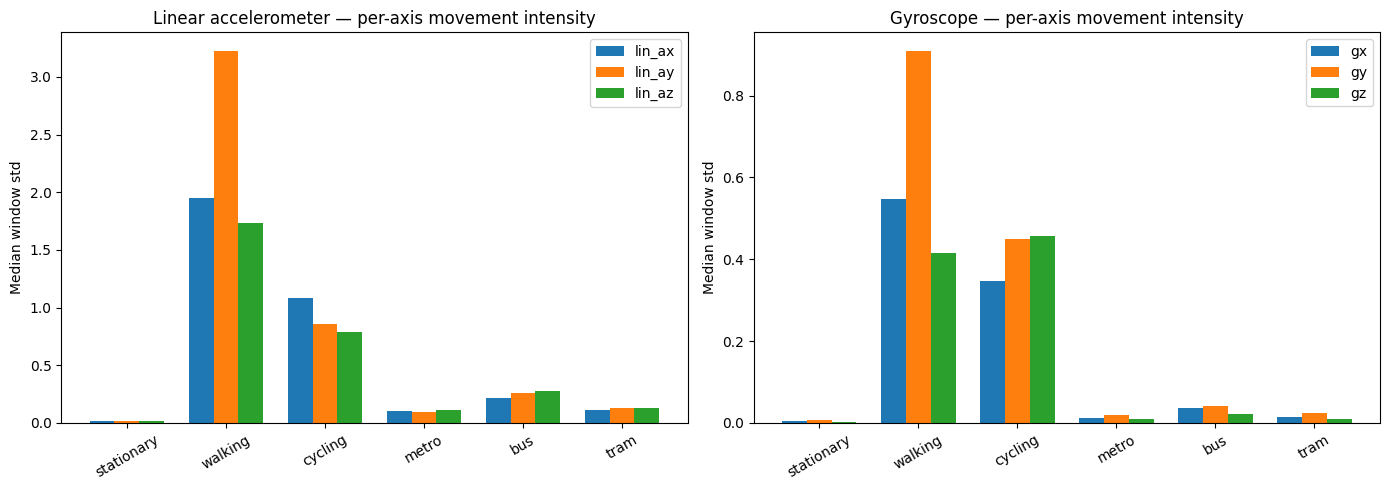

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

lin_cols = ['lin_ax_std', 'lin_ay_std', 'lin_az_std']
x = np.arange(len(MODES))
width = 0.25
for i, col in enumerate(lin_cols):
    axes[0].bar(x + (i - 1) * width, axis_mode_summary[col].values, width, label=col.replace('_std', ''))
axes[0].set_xticks(x)
axes[0].set_xticklabels(MODES, rotation=30)
axes[0].set_ylabel('Median window std')
axes[0].set_title('Linear accelerometer — per-axis movement intensity')
axes[0].legend()

gyro_cols = ['gx_std', 'gy_std', 'gz_std']
for i, col in enumerate(gyro_cols):
    axes[1].bar(x + (i - 1) * width, axis_mode_summary[col].values, width, label=col.replace('_std', ''))
axes[1].set_xticks(x)
axes[1].set_xticklabels(MODES, rotation=30)
axes[1].set_ylabel('Median window std')
axes[1].set_title('Gyroscope — per-axis movement intensity')
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_per_axis_intensity.png', dpi=300, bbox_inches='tight')
plt.show()

### Discussion of per-axis structure

Splitting magnitude back into individual axes reveals structure that the magnitude-only view obscures.
Walking is dominated by one or two axes rather than being uniformly large across all three, which is consistent with the directional nature of the stepping motion (vertical bouncing and forward/backward swing dominate over lateral motion). Cycling shows a different axis distribution from walking even when overall intensity is comparable, suggesting that the classifier can use axis ratios — not just magnitudes — to separate them.

The public-transport modes also differ from each other in their per-axis profiles even when overall magnitude is similar. This is the most encouraging observation for the bus/metro/tram disambiguation problem: features that preserve axis information (per-axis variance, axis correlations, principal-component ratios) are likely to be more informative than scalar magnitude features alone.

## 8. Representative signal visualisation

Summary statistics and boxplots provide a useful overview of the dataset, but they do not show how the signals evolve over time.

In this section we inspect representative recordings from each transport mode using the linear-accelerometer magnitude.

The linear accelerometer is particularly useful because it removes gravity and therefore focuses on actual movement.

The objective is to identify characteristic motion patterns associated with each transport mode and to assess whether these patterns are visually distinguishable.

### Select representative sessions

For each transport mode we select one representative session.

To keep the plots readable, only a single recording per mode is shown. The selected sessions are not intended to be special cases; they simply provide an example of the signal characteristics associated with each transport mode.

In [20]:
representative_sessions = {}
for mode in MODES:
    candidates = sessions[
        (sessions['mode'] == mode) &
        (sessions['participant'] == REPRESENTATIVE_PARTICIPANT)
    ]
    if len(candidates) == 0:
        # fall back to any participant if the chosen one is missing this mode
        candidates = sessions[sessions['mode'] == mode]
    representative_sessions[mode] = candidates['session_id'].iloc[0]

print(f'Representative sessions (all from {REPRESENTATIVE_PARTICIPANT} where available):')
for m, sid in representative_sessions.items():
    print(f'  {m:12s} -> {sid}')

Representative sessions (all from babis where available):
  stationary   -> babis_stationary_day1
  walking      -> babis_walking_day1
  cycling      -> babis_cycling_day1
  metro        -> babis_metro_day1
  bus          -> babis_bus_day1
  tram         -> babis_tram_day1


### 8.1a Linear-accelerometer magnitude over time

The following figure shows the linear-accelerometer magnitude for one representative session from each transport mode.

Higher values correspond to stronger movement.

We expect stationary recordings to remain relatively flat, while walking and cycling should exhibit stronger oscillatory patterns.

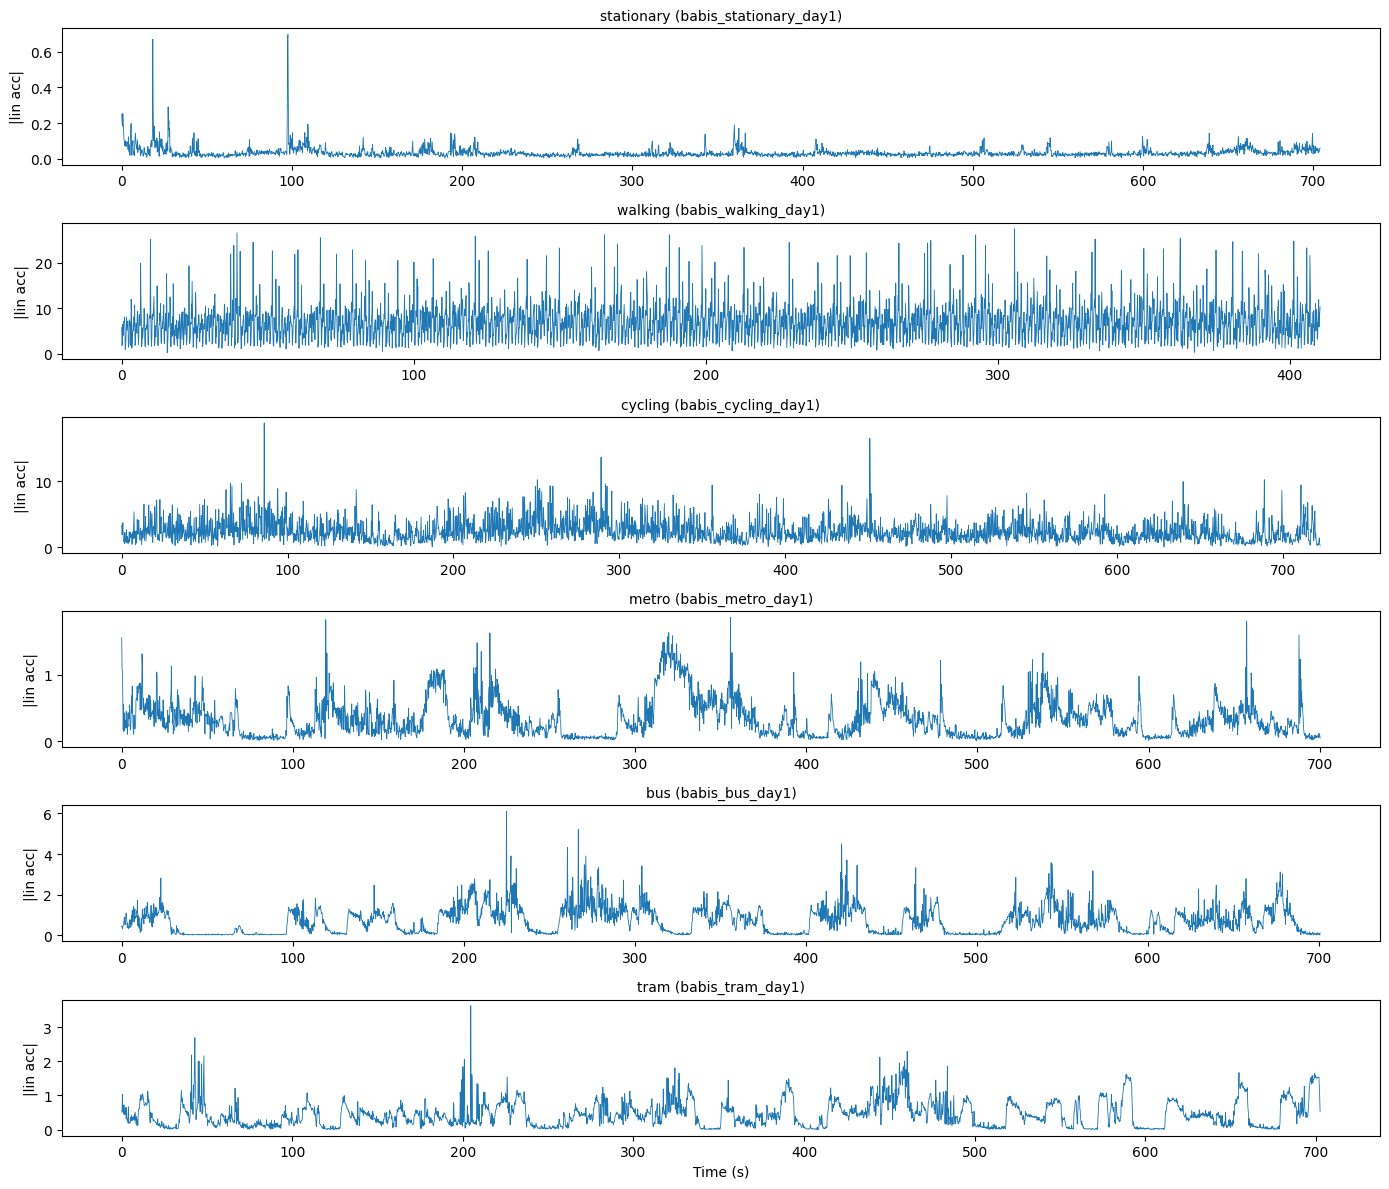

In [21]:
fig, axes = plt.subplots(len(MODES), 1, figsize=(14, 12), sharex=False)
for ax, mode in zip(axes, MODES):
    sid = representative_sessions[mode]
    sdf = data[data['session_id'] == sid]
    step = max(1, len(sdf) // 3000)
    ax.plot(sdf['t'][::step], sdf['lin_acc_mag'][::step], linewidth=0.6)
    ax.set_title(f'{mode} ({sid})', fontsize=10)
    ax.set_ylabel('|lin acc|')
axes[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_representative_lin_acc_signals.png', dpi=300, bbox_inches='tight')
plt.show()

### 8.1b Raw three-axis signals — one representative session per mode

Shows the individual x/y/z axes of the linear accelerometer for one session per mode.
raw sensor axes, not just magnitude.

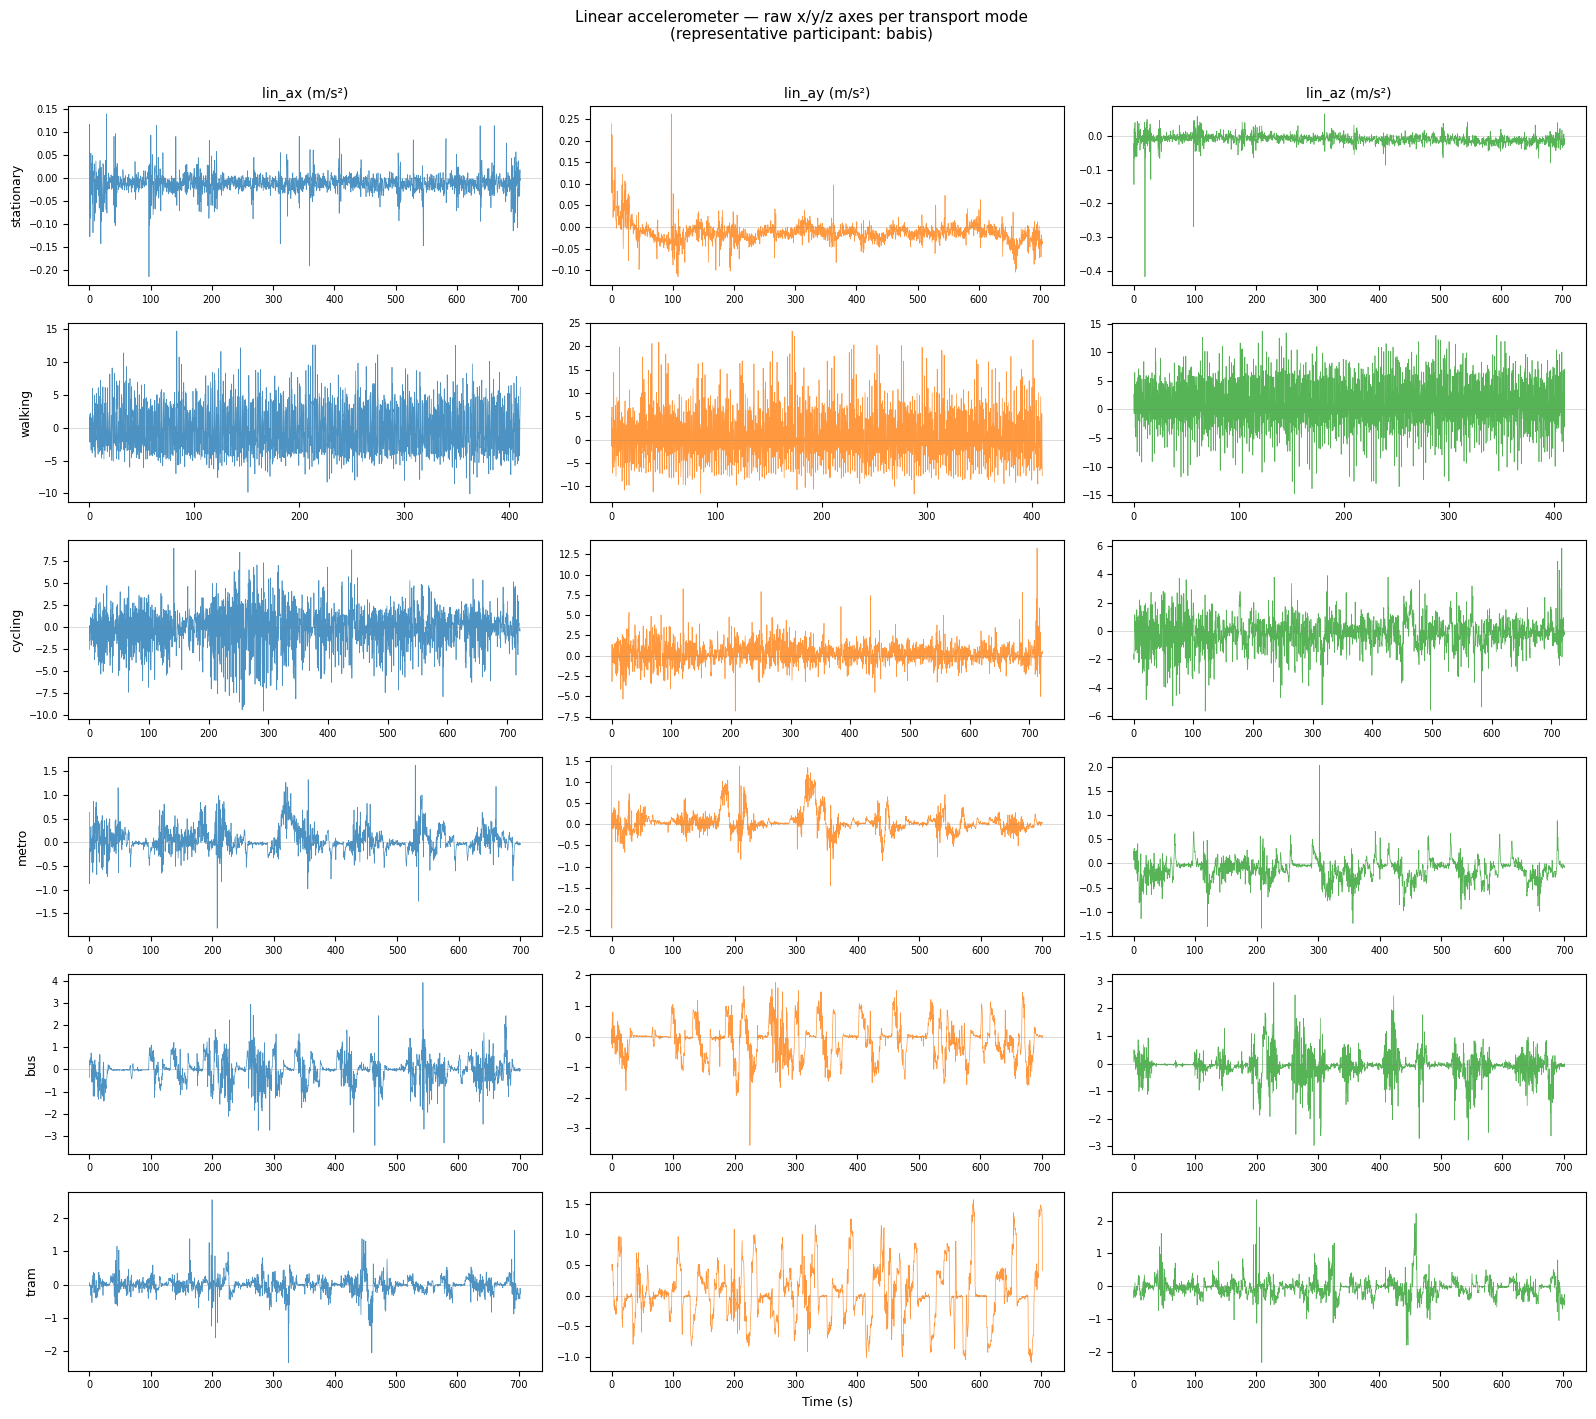

In [22]:
fig, axes = plt.subplots(len(MODES), 3, figsize=(16, 14), sharex=False)

for row_idx, mode in enumerate(MODES):
    sid = representative_sessions[mode]
    sdf = data[data['session_id'] == sid]
    step = max(1, len(sdf) // 2000)

    for col_idx, (col, label, color) in enumerate([
        ('lin_ax', 'x', 'tab:blue'),
        ('lin_ay', 'y', 'tab:orange'),
        ('lin_az', 'z', 'tab:green'),
    ]):
        ax = axes[row_idx, col_idx]
        ax.plot(sdf['t'].iloc[::step], sdf[col].iloc[::step],
                linewidth=0.5, color=color, alpha=0.8)
        ax.axhline(0, color='gray', linewidth=0.4, alpha=0.5)

        if row_idx == 0:
            ax.set_title(f'lin_a{label} (m/s²)', fontsize=10)
        if col_idx == 0:
            ax.set_ylabel(mode, fontsize=9)
        ax.tick_params(labelsize=7)

axes[-1, 1].set_xlabel('Time (s)', fontsize=9)

plt.suptitle(
    'Linear accelerometer — raw x/y/z axes per transport mode\n'
    f'(representative participant: {REPRESENTATIVE_PARTICIPANT})',
    y=1.01, fontsize=11
)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_representative_axes.png', dpi=300, bbox_inches='tight')
plt.show()

### 8.2 Zoomed 20-second excerpts

The full-session plots show the overall behaviour of each recording, but they are too long to clearly inspect short-term movement patterns.

To better understand the temporal structure of the signals, we now zoom into a 20-second segment from each representative recording.

This makes it easier to compare periodic motion, such as walking steps or cycling cadence, with the more irregular movement patterns observed in public transport.

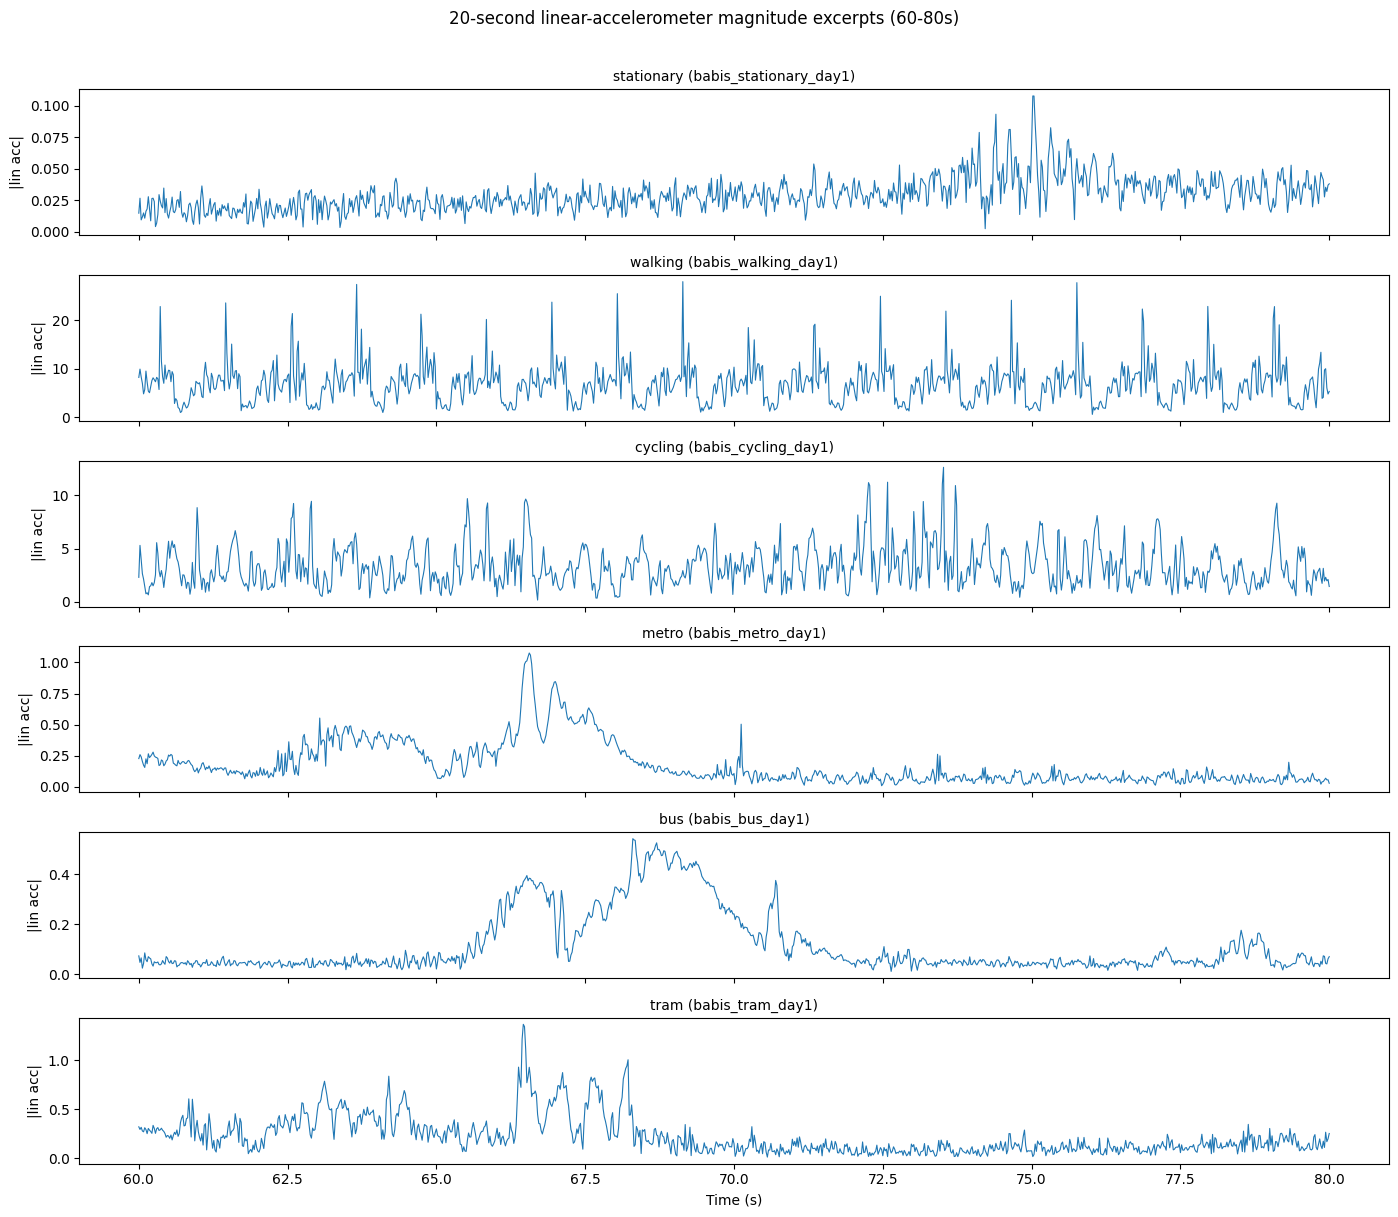

In [23]:
ZOOM_START_S    = 60
ZOOM_DURATION_S = 20
ZOOM_END_S      = ZOOM_START_S + ZOOM_DURATION_S

fig, axes = plt.subplots(len(MODES), 1, figsize=(14, 12), sharex=True)
for ax, mode in zip(axes, MODES):
    sid = representative_sessions[mode]
    sdf = data[(data['session_id'] == sid) & (data['t'] >= ZOOM_START_S) & (data['t'] <= ZOOM_END_S)]
    ax.plot(sdf['t'], sdf['lin_acc_mag'], linewidth=0.8)
    ax.set_title(f'{mode} ({sid})', fontsize=10)
    ax.set_ylabel('|lin acc|')
axes[-1].set_xlabel('Time (s)')
plt.suptitle(f'{ZOOM_DURATION_S}-second linear-accelerometer magnitude excerpts ({ZOOM_START_S}-{ZOOM_END_S}s)', y=1.01, fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_zoomed_lin_acc_signals.png', dpi=300, bbox_inches='tight')
plt.show()

### Discussion of representative signals

Because all representative sessions come from the same participant, differences in the plots reflect mode rather than individual variation.

Across the full sessions, the stationary recording remains close to zero for most of the period, indicating minimal movement. Walking exhibits sustained high-amplitude activity throughout, while cycling shows continuous movement of lower intensity. The public-transport modes display more irregular behaviour, with alternating periods of low activity and bursts of movement that likely correspond to acceleration, braking, road or track conditions, and passenger motion.

The zoomed excerpts reveal additional detail that is invisible at the full-session scale. Walking displays a highly regular, repetitive pattern with evenly spaced peaks consistent with stepping motion. Cycling also shows continuous fluctuations but with more variable peak timing and amplitude, suggesting a combination of pedalling motion and additional variability from riding conditions. The public-transport modes do not exhibit any clear periodic structure: metro, bus, and tram are characterised by irregular fluctuations and short bursts of movement separated by relatively stable periods. While these modes differ from walking and cycling, they appear considerably more similar to one another at the short time scale.

## 9. Frequency-domain exploration (window-level)

We compute FFT on 5-second windows — the same temporal scale the classification model will operate on — rather than on entire sessions. We then take the median spectrum across windows for each mode, which gives a robust estimate of typical spectral content while preserving the short-time character of the signal. The frequency range extends to the Nyquist frequency (25 Hz) rather than being truncated at 10 Hz; vehicular modes often carry useful vibration content at higher frequencies.

In [24]:
MAX_WINDOWS_PER_MODE = 200   # subsample for stability and speed
RNG = np.random.default_rng(0)

median_spectra = {}
for mode in MODES:
    spectra = []
    mode_sessions = data[data['mode'] == mode].groupby('session_id')
    for sid, sdf in mode_sessions:
        sig = sdf['lin_acc_mag'].values
        if len(sig) < WINDOW_SAMPLES:
            continue
        for start in range(0, len(sig) - WINDOW_SAMPLES + 1, STEP):
            w = sig[start:start + WINDOW_SAMPLES]
            w = w - w.mean()
            spec = np.abs(rfft(w))
            spectra.append(spec)
    spectra = np.asarray(spectra)
    if len(spectra) > MAX_WINDOWS_PER_MODE:
        idx = RNG.choice(len(spectra), size=MAX_WINDOWS_PER_MODE, replace=False)
        spectra = spectra[idx]
    median_spectra[mode] = np.median(spectra, axis=0)

freqs = rfftfreq(WINDOW_SAMPLES, d=1 / SAMPLING_RATE)
print(f'Frequency resolution: {freqs[1]:.2f} Hz, Nyquist: {freqs[-1]:.1f} Hz')
print(f'Windows sampled per mode: up to {MAX_WINDOWS_PER_MODE}')

Frequency resolution: 0.20 Hz, Nyquist: 25.0 Hz
Windows sampled per mode: up to 200


### 9.1 Median spectra per mode

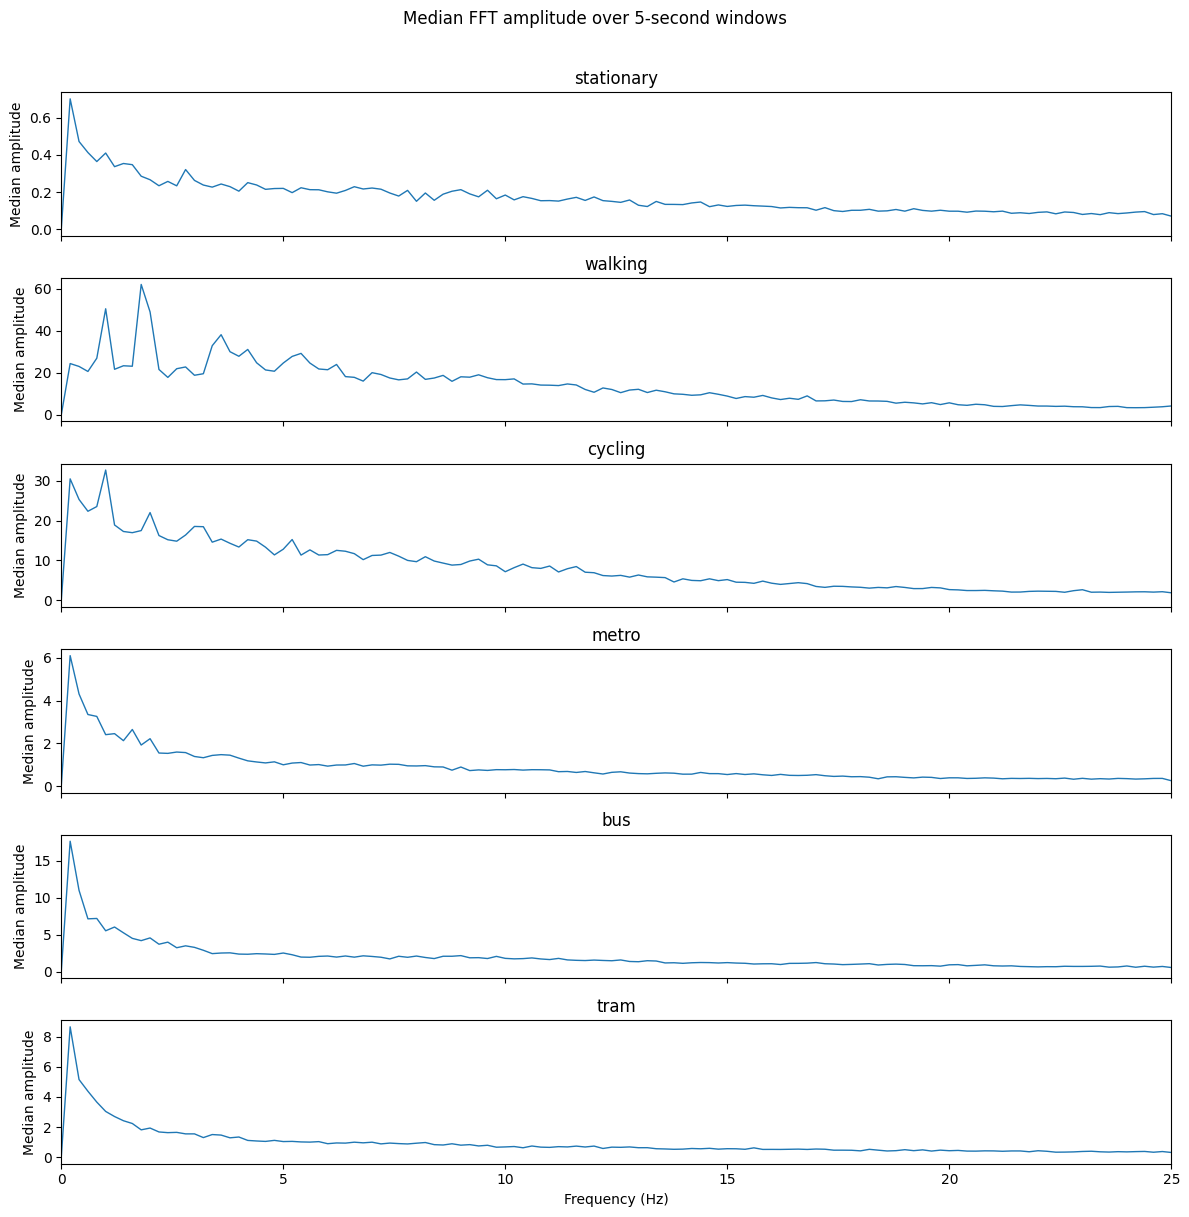

In [25]:
fig, axes = plt.subplots(len(MODES), 1, figsize=(12, 12), sharex=True)
for ax, mode in zip(axes, MODES):
    ax.plot(freqs, median_spectra[mode], linewidth=1)
    ax.set_title(mode)
    ax.set_ylabel('Median amplitude')
    ax.set_xlim(0, freqs[-1])
axes[-1].set_xlabel('Frequency (Hz)')
plt.suptitle('Median FFT amplitude over 5-second windows', y=1.01, fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_fft_median_per_mode.png', dpi=300, bbox_inches='tight')
plt.show()

### 9.2 Normalised comparison across selected modes

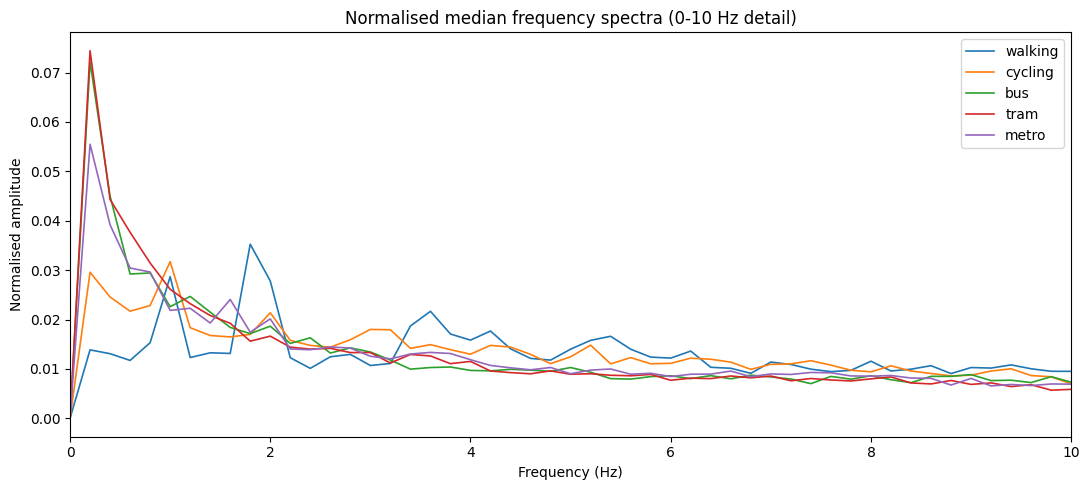

In [26]:
plt.figure(figsize=(11, 5))
comparison_modes = ['walking', 'cycling', 'bus', 'tram', 'metro']
for mode in comparison_modes:
    spec = median_spectra[mode]
    spec_norm = spec / spec.sum()
    plt.plot(freqs, spec_norm, label=mode, linewidth=1.2)
plt.xlim(0, 10)  # detail zoom on the most informative band
plt.title('Normalised median frequency spectra (0-10 Hz detail)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Normalised amplitude')
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_fft_normalized_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

### Discussion of frequency-domain analysis

Because the spectra are computed on 5-second windows and aggregated by median, they reflect the typical short-time spectral content of each mode rather than being dominated by occasional bursts or by very long-term trends. This makes the analysis directly comparable to what the classifier will operate on.

Walking exhibits pronounced spectral peaks in the 1.5–2.5 Hz range, corresponding to the typical step cadence of around 100–150 steps per minute. Harmonics at higher frequencies are also visible, reflecting the highly periodic nature of stepping. Cycling shows a clearly different spectral shape: it has a primary low-frequency peak associated with pedalling cadence but a broader distribution of energy across the spectrum, consistent with the more variable signal patterns observed in the time-domain plots.

The public-transport modes are dominated by low-frequency components and lack the strong periodic peaks seen in walking. Their spectra are smoother and less structured, indicating that movement is primarily driven by irregular events (acceleration, braking, track or road vibrations, passenger motion) rather than by repetitive body movement. The normalised comparison plot reveals subtler differences between bus, tram, and metro that may help disambiguate them: bus tends to carry slightly more mid-frequency content than metro, consistent with the higher road-surface vibration of buses compared with light-rail vehicles.

Together with the per-axis analysis, this suggests that frequency-domain features — dominant frequency, spectral entropy, band power in 1–3 Hz and 3–8 Hz ranges — should be priority features for the classifier.

## 10. Participant consistency

We assess whether the patterns identified above are stable across participants. Generalisation across users (E2 in the evaluation design) depends on this stability.

In [27]:
participant_summary = (
    windows_df.groupby(['participant', 'mode'])['lin_acc_mag_std']
    .agg(['mean', 'std', 'median'])
    .round(3)
)
participant_summary.to_csv(EDA_OUTPUT_DIR / 'eda_participant_summary.csv')
participant_summary

mean    std  median
participant mode                            
athina      bus         0.316  0.282   0.231
            cycling     0.536  0.312   0.429
            metro       0.129  0.120   0.103
            stationary  0.057  0.049   0.038
            tram        0.142  0.143   0.100
            walking     1.324  0.257   1.286
babis       bus         0.368  0.243   0.351
            cycling     1.448  0.454   1.349
            metro       0.147  0.134   0.125
            stationary  0.015  0.040   0.008
            tram        0.208  0.190   0.163
            walking     3.560  0.520   3.566
xiomara     bus         0.310  0.260   0.246
            cycling     0.916  0.506   0.765
            metro       0.104  0.127   0.082
            stationary  0.025  0.035   0.017
            tram        0.151  0.139   0.119
            walking     1.487  0.355   1.535

### 10.1 Per-participant boxplots within mode

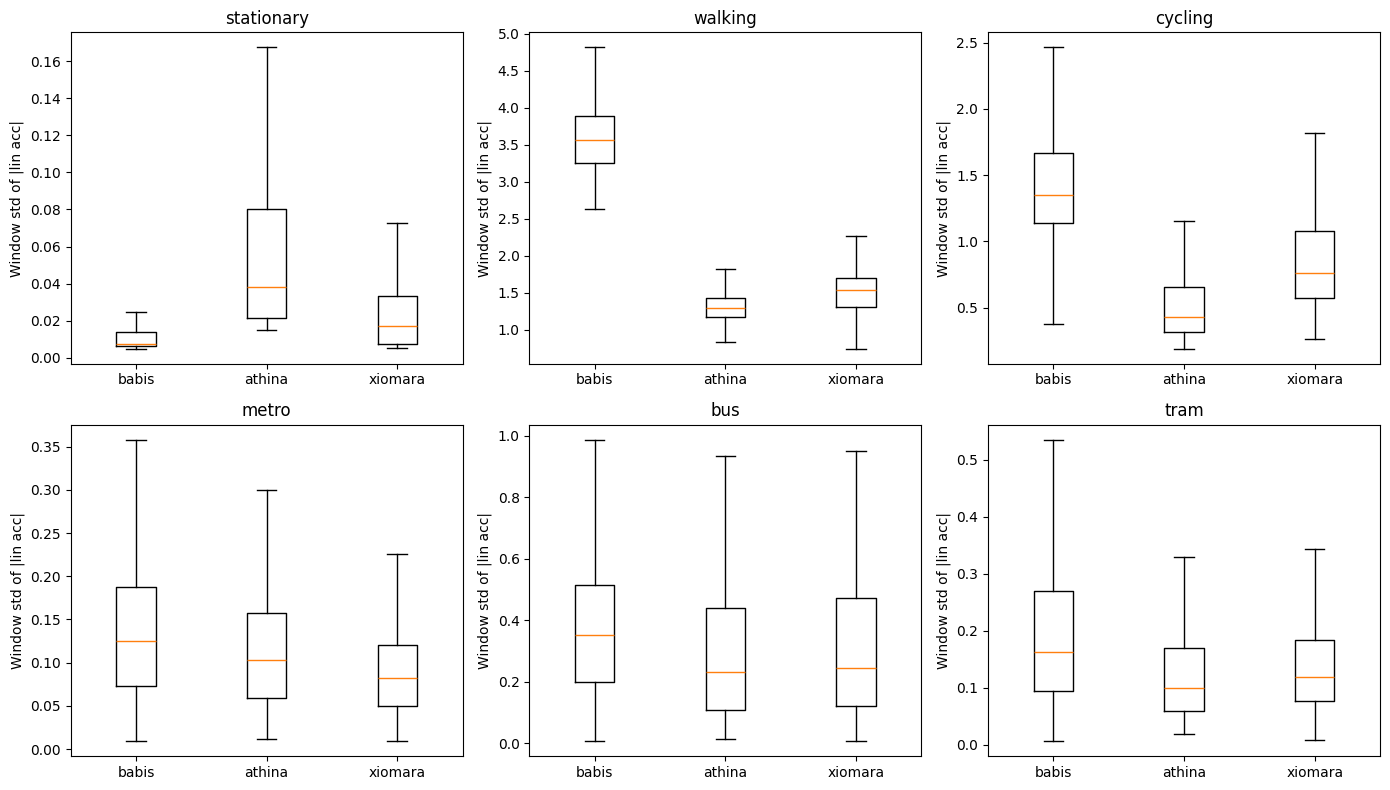

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()
for ax, mode in zip(axes, MODES):
    plot_data = [
        windows_df.loc[(windows_df['participant'] == p) & (windows_df['mode'] == mode), 'lin_acc_mag_std']
        for p in PARTICIPANTS
    ]
    ax.boxplot(plot_data, tick_labels=PARTICIPANTS, showfliers=False)
    ax.set_title(mode)
    ax.set_ylabel('Window std of |lin acc|')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_participant_consistency.png', dpi=300, bbox_inches='tight')
plt.show()

### 10.2 Participant × mode heatmap (z-scored within column)

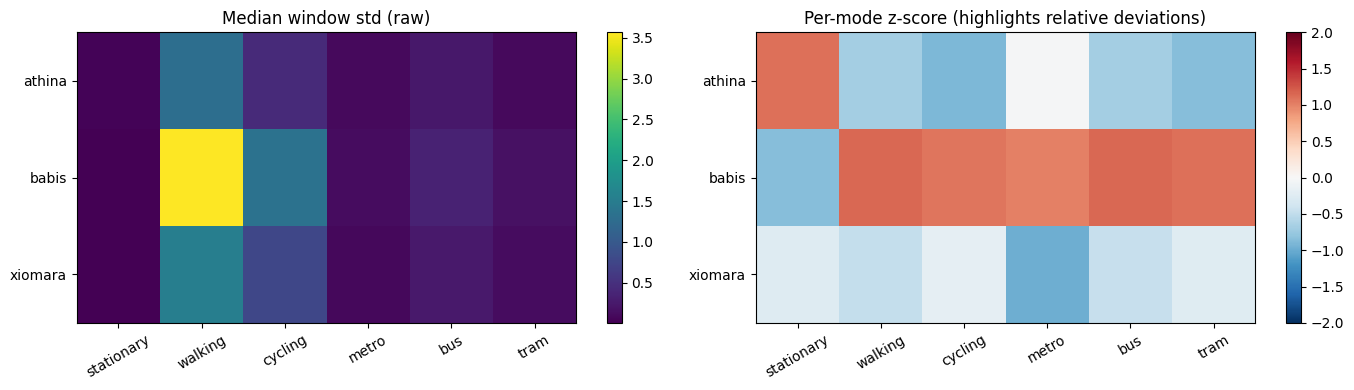

In [29]:
heatmap_raw = (
    windows_df.groupby(['participant', 'mode'])['lin_acc_mag_std']
    .median()
    .unstack()
    .reindex(columns=MODES)
)
# Z-score within each mode column to expose relative differences across participants
heatmap_z = heatmap_raw.apply(lambda c: (c - c.mean()) / (c.std() + 1e-9), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
im0 = axes[0].imshow(heatmap_raw.values, aspect='auto', cmap='viridis')
axes[0].set_xticks(range(len(MODES))); axes[0].set_xticklabels(MODES, rotation=30)
axes[0].set_yticks(range(len(heatmap_raw.index))); axes[0].set_yticklabels(heatmap_raw.index)
axes[0].set_title('Median window std (raw)')
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(heatmap_z.values, aspect='auto', cmap='RdBu_r', vmin=-2, vmax=2)
axes[1].set_xticks(range(len(MODES))); axes[1].set_xticklabels(MODES, rotation=30)
axes[1].set_yticks(range(len(heatmap_z.index))); axes[1].set_yticklabels(heatmap_z.index)
axes[1].set_title('Per-mode z-score (highlights relative deviations)')
plt.colorbar(im1, ax=axes[1])

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_participant_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

### Discussion of participant consistency

Individual-level differences are clearly present in the dataset. Some participants generate consistently larger movement magnitudes than others across multiple modes, reflecting natural variation in walking pace, cycling cadence, phone placement, and posture. The z-scored heatmap makes these relative differences easier to see than the raw values: positive cells indicate a participant who moves more than average for that mode, negative cells the opposite.

Critically, however, the *relative ordering* of transport modes remains stable across all participants. Stationary recordings sit at the bottom for every individual; walking sits at the top; cycling consistently lies above the public-transport modes. This stability suggests that the dominant patterns identified throughout the EDA are primarily associated with the transport mode rather than with the specific participant, and gives some optimism that a classifier trained on a subset of participants will retain its ranking of mode signatures on held-out users.

That said, the absolute differences between participants are not trivial. We can expect leave-one-user-out evaluation (E2) to drop noticeably below random-split (E0). The calibration experiment (E5) is therefore well-motivated: a small adaptation sample from a new user is likely to recover much of the lost accuracy, because per-participant offsets are systematic rather than chaotic.

## 11. PCA projection of session-level features

A canonical EDA plot for activity-recognition problems: aggregate each session to a short feature vector, project to 2D with PCA, and colour by mode. If sessions of the same mode cluster together, the dataset is visually separable and the classifier has a real chance.
Each session contributes one point. We use the same participant marker to also assess whether mode clusters are consistent across users.

In [30]:
# Per-session aggregated feature vector
def session_features(sdf):
    feats = {}
    for col in ['lin_acc_mag', 'gyro_mag', 'acc_mag']:
        feats[f'{col}_mean']   = float(sdf[col].mean())
        feats[f'{col}_std']    = float(sdf[col].std())
        feats[f'{col}_median'] = float(sdf[col].median())
        feats[f'{col}_iqr']    = float(np.percentile(sdf[col], 75) - np.percentile(sdf[col], 25))
    # dominant frequency (whole-session, used here only as a coarse feature)
    sig = sdf['lin_acc_mag'].values - sdf['lin_acc_mag'].mean()
    spec = np.abs(rfft(sig))
    fs   = rfftfreq(len(sig), d=1 / SAMPLING_RATE)
    valid = fs > 0.2  # ignore DC band
    feats['dominant_freq_hz'] = float(fs[valid][np.argmax(spec[valid])])
    return feats

session_feature_rows = []
for sid, sdf in data.groupby('session_id'):
    f = session_features(sdf)
    f.update({
        'session_id': sid,
        'participant': sdf['participant'].iloc[0],
        'mode': sdf['mode'].iloc[0],
        'day': sdf['day'].iloc[0],
    })
    session_feature_rows.append(f)

session_features_df = pd.DataFrame(session_feature_rows)
session_features_df.to_csv(EDA_OUTPUT_DIR / 'eda_session_features.csv', index=False)
print(f'Session feature matrix: {session_features_df.shape}')

Session feature matrix: (54, 17)


Variance explained: PC1=84.33%  PC2=7.78%  total=92.12%


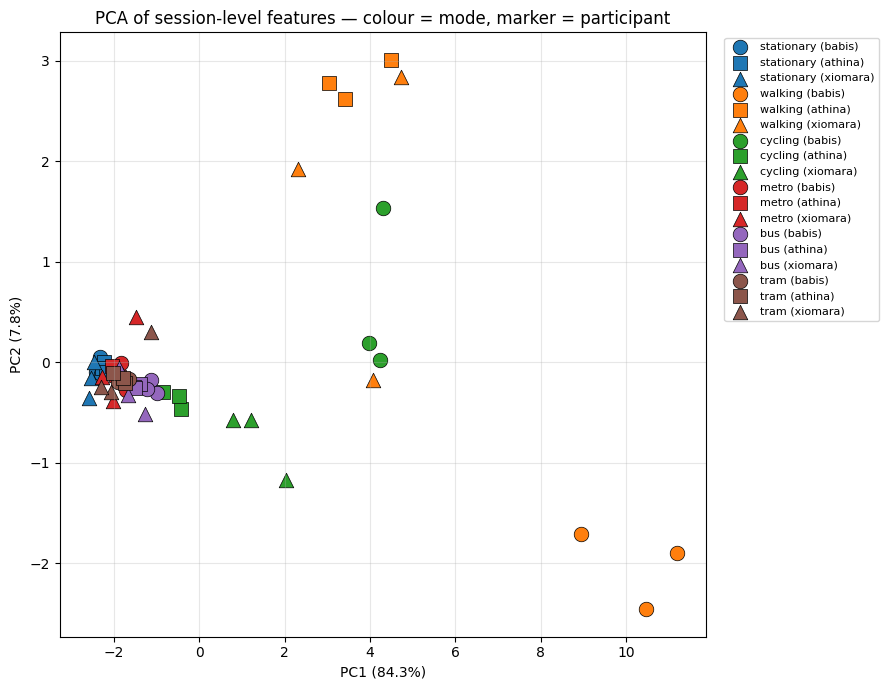

In [31]:
feature_cols = [c for c in session_features_df.columns
                if c not in {'session_id', 'participant', 'mode', 'day'}]
X = StandardScaler().fit_transform(session_features_df[feature_cols].values)

pca = PCA(n_components=2)
components = pca.fit_transform(X)
print(f'Variance explained: PC1={pca.explained_variance_ratio_[0]:.2%}  '
      f'PC2={pca.explained_variance_ratio_[1]:.2%}  '
      f'total={pca.explained_variance_ratio_.sum():.2%}')

fig, ax = plt.subplots(figsize=(9, 7))
mode_colors = {m: c for m, c in zip(MODES, plt.cm.tab10.colors)}
participant_markers = {p: m for p, m in zip(PARTICIPANTS, ['o', 's', '^'])}

for mode in MODES:
    for participant in PARTICIPANTS:
        mask = ((session_features_df['mode'] == mode) &
                (session_features_df['participant'] == participant))
        if not mask.any():
            continue
        ax.scatter(components[mask, 0], components[mask, 1],
                   c=[mode_colors[mode]], marker=participant_markers[participant],
                   s=110, edgecolor='black', linewidth=0.5,
                   label=f'{mode} ({participant})')

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
ax.set_title('PCA of session-level features — colour = mode, marker = participant')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'eda_pca_session_features.png', dpi=300, bbox_inches='tight')
plt.show()

### Discussion of PCA projection

The PCA projection compresses ~13 per-session summary features into two dimensions while preserving most of the variance.
Three observations are most relevant for modelling:

First, **mode clusters are visually distinguishable** in this 2D view, with stationary, walking, and cycling each occupying separate regions of feature space. This is the most encouraging sign of classifier feasibility: sessions of the same mode generally cluster together even with only simple summary features and no temporal modelling.

Second, **the public-transport modes overlap most strongly** with each other, sitting in a middle region of the projection. This confirms the H2 hypothesis from the plan that bus/metro/tram will be the hardest pairwise discrimination problem. Notably, this overlap exists at the session level even before windowing — at the window level the overlap may be even larger due to within-trip variability.

Third, **the same mode from different participants generally clusters together** (compare marker shapes within a colour group). This is consistent with the participant-consistency analysis: while individuals have offsets, the mode structure dominates. If user-shift had been catastrophic, we would expect markers of different shapes to scatter across the projection regardless of colour.

## 12. Barometer exploration

Barometer data is available for participants Babis and Xiomara (Athina's phone did not export pressure).
Even though the barometer is excluded from the main cross-user model — including it would leak participant identity, since one participant lacks the sensor — exploring its behaviour is informative.
Metro journeys in particular often involve underground sections with measurable pressure changes; bus and walking should show very little pressure variation.

In [32]:
baro_data = data.dropna(subset=['pressure'])
print(f'Sessions with barometer data: {baro_data["session_id"].nunique()}')
print(f'Participants with barometer: {sorted(baro_data["participant"].unique())}')

if len(baro_data) == 0:
    print('No barometer data available — skipping this section.')
else:
    baro_summary = (
        baro_data.groupby('mode')['pressure']
        .agg(['mean', 'std', 'min', 'max'])
        .round(3)
        .reindex(MODES)
    )
    baro_summary['range'] = (baro_summary['max'] - baro_summary['min']).round(3)
    baro_summary.to_csv(EDA_OUTPUT_DIR / 'eda_barometer_summary.csv')
    print()
    print('Barometer descriptive statistics by mode:')
    print(baro_summary.to_string())

Sessions with barometer data: 36
Participants with barometer: ['babis', 'xiomara']

Barometer descriptive statistics by mode:
                mean    std      min       max   range
mode                                                  
stationary  1004.268  6.738  994.381  1013.538  19.157
walking     1004.841  6.284  998.220  1016.834  18.614
cycling     1005.552  7.042  997.916  1017.910  19.994
metro       1005.318  6.600  997.103  1019.718  22.615
bus         1007.271  7.034  997.556  1019.571  22.015
tram        1007.853  6.582  997.508  1017.521  20.013


In [33]:
if len(baro_data) > 0:
    # Per-session pressure variability, then aggregated by mode.
    # This isolates within-session altitude-driven changes from
    # between-session weather drift, which the previous summary mixed together.
    per_session_baro = (
        baro_data.groupby(['mode', 'session_id'])['pressure']
        .agg(['min', 'max', 'std'])
    )
    per_session_baro['range'] = per_session_baro['max'] - per_session_baro['min']

    baro_within = (
        per_session_baro.groupby('mode')[['range', 'std']]
        .median()
        .round(3)
        .reindex(MODES)
        .rename(columns={'range': 'median_within_session_range',
                         'std':   'median_within_session_std'})
    )
    baro_within.to_csv(EDA_OUTPUT_DIR / 'eda_barometer_within_session.csv')
    print('Within-session pressure variability (median across sessions per mode):')
    print(baro_within.to_string())

Within-session pressure variability (median across sessions per mode):
            median_within_session_range  median_within_session_std
mode                                                              
stationary                        0.296                      0.051
walking                           0.626                      0.109
cycling                           0.909                      0.189
metro                             4.913                      1.179
bus                               0.834                      0.127
tram                              0.540                      0.104


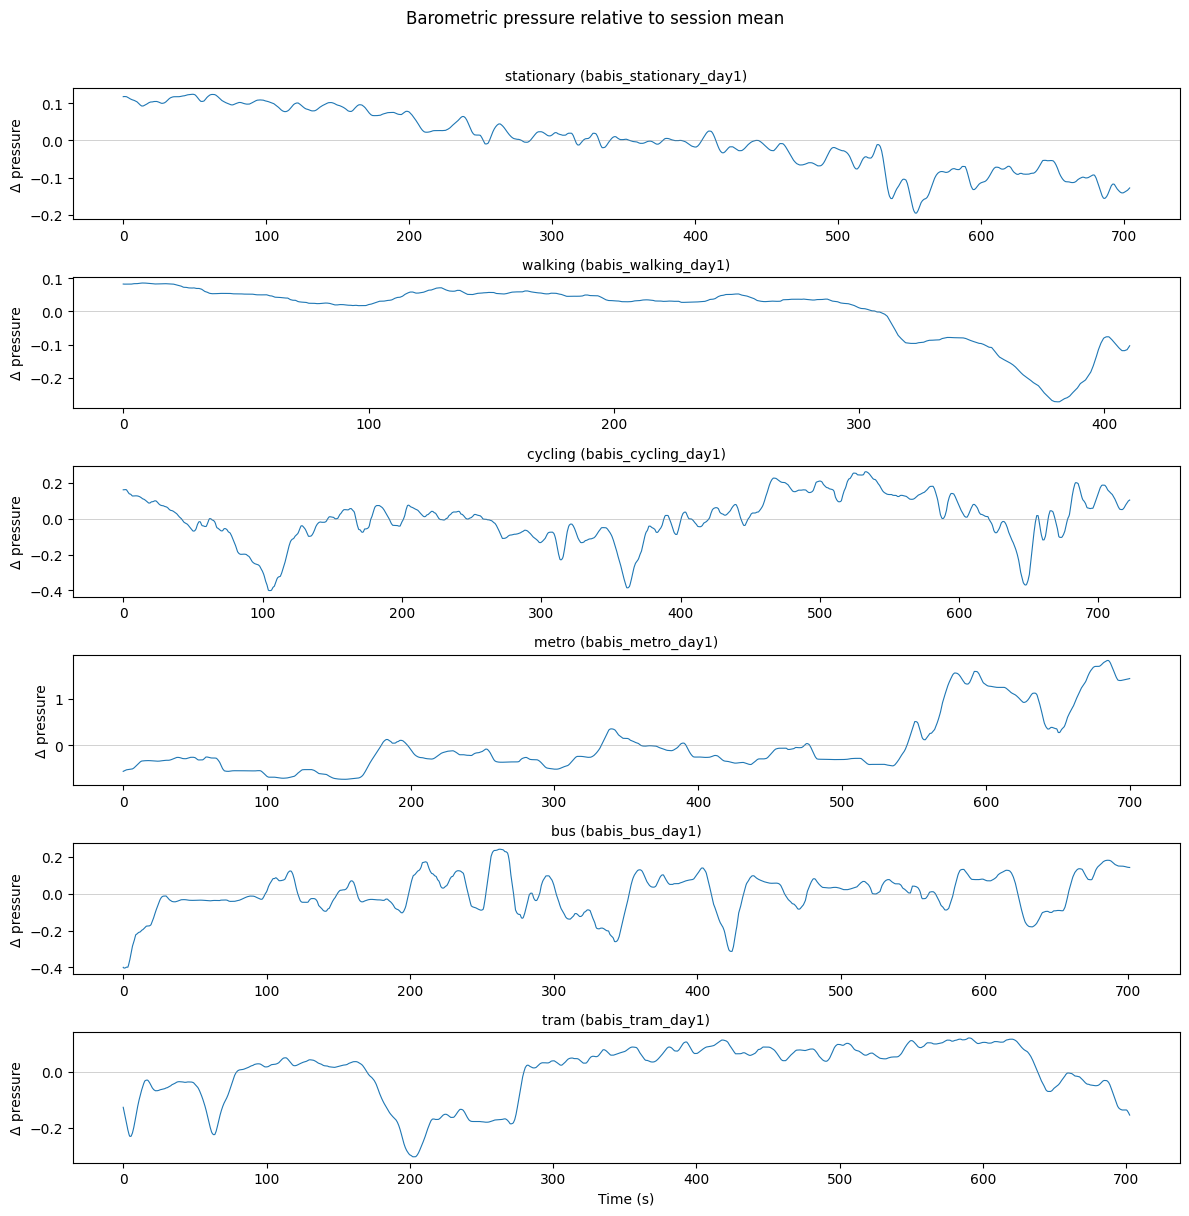

In [34]:
if len(baro_data) > 0:
    # Pick one session per mode that has barometer data, for visualisation
    baro_sessions = {}
    for mode in MODES:
        candidates = baro_data[baro_data['mode'] == mode]
        if len(candidates) > 0:
            baro_sessions[mode] = candidates['session_id'].iloc[0]

    fig, axes = plt.subplots(len(baro_sessions), 1, figsize=(12, 2 * len(baro_sessions)), sharex=False)
    if len(baro_sessions) == 1:
        axes = [axes]
    for ax, (mode, sid) in zip(axes, baro_sessions.items()):
        sdf = baro_data[baro_data['session_id'] == sid]
        # subtract mean to make changes visible on a common axis range
        p_centered = sdf['pressure'] - sdf['pressure'].mean()
        step = max(1, len(sdf) // 1500)
        ax.plot(sdf['t'].iloc[::step], p_centered.iloc[::step], linewidth=0.8)
        ax.set_title(f'{mode} ({sid})', fontsize=10)
        ax.set_ylabel('Δ pressure')
        ax.axhline(0, color='gray', linewidth=0.5, alpha=0.5)
    axes[-1].set_xlabel('Time (s)')
    plt.suptitle('Barometric pressure relative to session mean', y=1.01, fontsize=12)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'eda_barometer_signals.png', dpi=300, bbox_inches='tight')
    plt.show()

### Discussion of barometer signals

The two summary tables in this section measure different things, and only one reflects what the barometer can actually contribute to mode classification. The first table aggregates pressure across all samples of all sessions in a mode, so it is dominated by between-session weather drift — six stationary recordings on six different days will span a wider absolute pressure range than a single metro journey, even though only the journey contains a real altitude signal. The within-session table corrects for this by computing variability inside each session and taking the median across sessions per mode.

On the corrected view, metro stands clearly apart: its median within-session pressure range of 4.91 hPa is roughly five times larger than any other mode, and its within-session standard deviation (1.20 hPa) is six times the next highest. The time-series plot for the Babis metro session makes the mechanism visible — pressure sits stably around −0.5 hPa relative to the session mean for the first 500 seconds, then climbs by more than 2 hPa over the final minutes as the journey surfaces from underground. The remaining modes cluster between 0.35 and 1.06 hPa of within-session range with no clean ordering between them; cycling (0.91 hPa range, 0.19 hPa std) shows somewhat more consistent variability than bus, tram, and walking, plausibly reflecting elevation changes on Amsterdam's bridges and canal slopes, but the gap is too small to support reliable discrimination. Stationary is the lowest on both metrics, which is the physically expected baseline.

These observations are encouraging but cannot enter the main cross-user model: Athina's phone does not record barometer, so any pressure-derived feature would leak participant identity into the LOSO splits. We will therefore run a small ablation in the modelling notebooks — train a classifier on the barometer-available subset (Babis and Xiomara), with and without pressure-derived features. The result is interpretable only within that subset, but provides a useful sanity check on the barometer's discriminative value, with a specific expectation that metro precision and recall will improve most.

## 13. EDA Summary and Feature-Engineering Implications

This notebook explored the processed smartphone sensor dataset with the objective of understanding its structure, identifying characteristic movement patterns, and assessing its suitability for transport-mode classification.

**Dataset structure.** The dataset contains 36 recording sessions distributed evenly across six transport modes and three participants. After preprocessing, the dataset provides over a million sensor samples at a uniform 50 Hz sampling rate. The class distribution is balanced at the session level, reducing the risk of bias toward particular modes during model development.

**Movement intensity.** Window-level magnitude analysis revealed substantial differences in movement intensity between transport modes. Stationary recordings exhibit minimal movement, while walking generates the highest linear-accelerometer and gyroscope magnitudes. Cycling also displays elevated movement intensity, whereas the public-transport modes occupy an intermediate range. Bus, metro, and tram differ slightly in their distributions, but considerable overlap remains.

**Temporal structure.** Representative signal visualisations showed sustained movement throughout walking and cycling activities, while the public-transport modes were characterised by alternating periods of low activity and movement bursts. Zoomed excerpts revealed strong periodic behaviour during walking, moderate periodicity during cycling, and predominantly irregular movement patterns during metro, bus, and tram journeys.

**Spectral structure.** Window-level FFT analysis confirmed and refined these observations. Walking exhibited distinct spectral peaks around 1.5–2.5 Hz with harmonics extending higher. Cycling displayed a broader frequency distribution with a lower-frequency primary peak. The public-transport modes were dominated by low-frequency components and lacked strong periodic structure, with subtle differences between bus, tram, and metro in the mid-frequency content.

**Per-axis structure.** Splitting magnitudes back into individual axes exposed structure that scalar magnitudes hide. Walking and cycling differ not only in overall intensity but in their per-axis distributions; the public-transport modes show distinct axis profiles even when overall magnitude is similar. This argues that features preserving axis information will be more informative than magnitude-only features.

**Participant variation.** Per-participant analysis demonstrated individual differences in absolute magnitudes, but the relative ordering of transport modes remained stable across all three participants. This is encouraging for cross-user generalisation but does not eliminate the user-shift problem: we expect E2 (leave-one-user-out) to drop noticeably below E0 (random split), and the calibration experiment (E5) is well-motivated.

**Overall separability.** The 2D PCA projection of session-level features showed visually distinct clusters for stationary, walking, and cycling, with the public-transport modes overlapping in a central region. Same-mode sessions from different participants generally clustered together, supporting the conclusion that the signal is primarily mode-driven.

### Implications for feature engineering

Based on these findings, the next notebook will prioritise the following feature families:

1. **Time-domain statistics on each window** (per-axis as well as magnitude): mean, std, median, IQR, RMS, signal-magnitude area. The window-level magnitude analysis showed these have strong per-mode discriminative power.
2. **Frequency-domain features**: dominant frequency, spectral entropy, and band-power features in 1–3 Hz, 3–8 Hz, and 8–20 Hz ranges. The frequency analysis showed clearly different spectral signatures across modes.
3. **Axis-relationship features**: per-axis variance ratios, axis correlations, principal-component-based descriptors. The per-axis analysis showed that the bus/metro/tram disambiguation likely depends on these.
4. **Distributional-shape features**: skewness, kurtosis, percentile ratios. The violin plots highlighted strong right-skew in the vehicular modes that mean-based features cannot capture.
5. **Optional barometer features** for an ablation on the barometer-available subset only.

The classification challenge is expected to follow this difficulty ranking: easy (stationary, walking), moderate (cycling), and hardest (bus/metro/tram disambiguation). The modelling notebook will report the confusion matrix structure to verify these EDA-derived predictions.